# WikiText Jacobian lens for GPT-2 XL (Neuronpedia recipe, fp16 autocast)

**Question.** Can GPT-2 XL get a J-lens fitted the same way as the published
Neuronpedia lenses (`neuronpedia/jacobian-lens`, `*/jlens/Salesforce-wikitext`), so that
its benchmarks are comparable with the Qwen and Gemma lenses? The Hub has such a lens only for GPT-2 small.

**Answer.** Yes. Fitted on WikiText-103 with the Neuronpedia recipe, the lens met the
stop rule at **339 prompts** (10-prompt mean `Δmean` 0.00198 < 0.002; `Δmean` first fell below
0.01 at 63 prompts and below 0.005 at 129), in 2.35 GPU-hours on a V100. Matrix products ran in
fp16 autocast: on one prompt this changes `J` by 7e-5–1.9e-3 relative to fp32 (median 4.7e-4),
against 0.11–1.31 between the Jacobians of two different prompts, and is 2.8× faster
(22 s vs 61 s per prompt). Only `dim_batch=8` fits in 16 GB.

The fitted lens is written to `runs/gpt2-xl-wikitext/gpt2-xl_jacobian_lens.pt` with a
provenance sidecar and the per-prompt convergence CSV. It is the default lens of
[the bootstrap benchmark](../latent_bridge_v2/latent_bridge_v2_lens_benchmark_bootstrap.ipynb).

## Method

The fit follows Neuronpedia `fit_lens.py`, the script behind every
`Salesforce-wikitext` lens on the Hub (its `config.yaml` records the exact command):

| | Neuronpedia (GPT-2 small) | this notebook (GPT-2 XL) |
|---|---|---|
| corpus | `Salesforce/wikitext`, `wikitext-103-raw-v1`, train | same |
| prompts | records joined and cut into 2000-character chunks; blank lines and `=` headers dropped | same (`jlens.convergence.chunk_texts`) |
| tokens | `max_seq_len=128` | same; BOS (`<|endoftext|>`) + first 127 tokens |
| estimator | `jlens.fit`, all-later-targets reduction, `skip_first=16`, target = final block | same |
| stop rule | at most 1000 prompts; stop when the mean `Δmean` of the last 10 prompts is < 0.002, not before 100 prompts | same (`jlens.convergence.ConvergenceTracker`) |
| precision | bf16 weights | fp32 weights under fp16 autocast |
| `dim_batch` | 128 (B200) | fastest that fits a V100, measured below |

`Δmean` is the relative Frobenius change of the running-mean Jacobian contributed by the
latest prompt, averaged over the 47 fitted layers (`jlens.FitProgress.mean_rel_change`,
same definition as upstream); it falls roughly like `1/n`.

**Deviations.** The V100 has no fast bf16, so matrix products run in fp16 autocast while
weights, layer norms and the residual stream stay fp32. A check on one prompt below measures how much
this changes `J` relative to fp32. `dim_batch` only changes speed and memory, not the estimate.
WikiText's raw tokenization artifacts (`@-@`, `@,@`) are kept, as in the reference recipe.

**Caching.** Prompts, the precision check, the `dim_batch` benchmark, the resumable fit
checkpoint and the final lens all live in `RUN_DIR`; each step is skipped when its output
exists, so re-executing the notebook after the fit loads nothing but the lens and CSV.

## Setup

In [1]:
import json
import os
import sys
import time
from pathlib import Path

REPO = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jlens" / "convergence.py").is_file()), None,
)
if REPO is None:
    raise RuntimeError("Open this notebook from a repository checkout that has jlens/convergence.py.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from IPython.display import display
from tqdm.auto import tqdm

import jlens
from gpt2 import GPT2LensModel
from jlens.convergence import ConvergenceTracker, load_chunked_prompts
from jlens.fitting import jacobian_for_prompt

pd.set_option("display.width", 200)

In [3]:
MODEL_ID = "openai-community/gpt2-xl"
DEVICE = "cuda"
AUTOCAST_DTYPE = torch.float16  # weights stay fp32
DATASET = dict(dataset="Salesforce/wikitext", config="wikitext-103-raw-v1", split="train",
               text_field="text", max_chars=2000)
N_PROMPTS = 1000
MAX_SEQ_LEN = 128
STOP = dict(stop_at_delta=0.002, min_prompts=100, window=10, levels=(1e-2, 5e-3, 1e-3))
DIM_BATCH_CANDIDATES = (8, 16, 32)
CHECKPOINT_EVERY = 5  # each checkpoint is ~0.5 GB (47 × 1600² fp32)
RUN_DIR = Path(os.environ.get("JLENS_RUN_DIR", REPO / "runs/gpt2-xl-wikitext"))
LENS_PATH = RUN_DIR / "gpt2-xl_jacobian_lens.pt"
CHECKPOINT_PATH = RUN_DIR / "gpt2-xl_checkpoint.pt"
CSV_PATH = RUN_DIR / "gpt2-xl_convergence.csv"
RUN_DIR.mkdir(parents=True, exist_ok=True)
if not LENS_PATH.exists() and not torch.cuda.is_available():
    raise RuntimeError("Fitting needs a CUDA GPU; with a finished lens this notebook runs on CPU.")
jlens.configure_logging("WARNING")  # per-prompt progress comes from the bar below
print(RUN_DIR)

/workspace/jlens-wiki/runs/gpt2-xl-wikitext


## 1. Fit prompts

Up to `N_PROMPTS` chunks, streamed once and cached; the fit stops earlier when it converges.

In [4]:
prompts_path = RUN_DIR / "prompts.json"
if prompts_path.exists():
    prompts = json.loads(prompts_path.read_text())
else:
    prompts = load_chunked_prompts(**DATASET, n_prompts=N_PROMPTS)
    prompts_path.write_text(json.dumps(prompts, ensure_ascii=False) + "\n")
tokenizer = transformers.AutoTokenizer.from_pretrained(MODEL_ID)
n_tokens = pd.Series([len(tokenizer(p).input_ids) for p in prompts])
print(f"{len(prompts)} prompts; characters {min(map(len, prompts))}–{max(map(len, prompts))}; "
      f"tokens min {n_tokens.min()}, median {n_tokens.median():.0f} (each truncated to {MAX_SEQ_LEN - 1} + BOS)")
print(repr(prompts[0][:300]))

1000 prompts; characters 1998–2000; tokens min 343, median 427 (each truncated to 127 + BOS)
'Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in Janua'


## 2. Precision and `dim_batch`

Both checks need the model and run only while the lens is missing. The precision check
fits prompt 0 in fp32 and under fp16 autocast and reports, per layer, the relative Frobenius
difference `‖J_fp16 − J_fp32‖ / ‖J_fp32‖`. For scale, the same quantity between two
different prompts' Jacobians is shown too: the fit averages over prompts that differ by
far more than the precision error.

In [5]:
_model = None


def get_model() -> GPT2LensModel:
    global _model
    if _model is None:
        _model = GPT2LensModel.from_pretrained(MODEL_ID, device=DEVICE)
    return _model


precision_path = RUN_DIR / "precision_check.json"
benchmark_path = RUN_DIR / "dim_batch_benchmark.json"
if not LENS_PATH.exists():
    model = get_model()
    layers = list(range(model.n_layers - 1))
    if not precision_path.exists():
        def timed(prompt, autocast):
            started = time.perf_counter()
            with torch.autocast("cuda", dtype=AUTOCAST_DTYPE, enabled=autocast):
                J, _, _ = jacobian_for_prompt(model, prompt, layers, dim_batch=8, max_seq_len=MAX_SEQ_LEN)
            return J, time.perf_counter() - started

        J32, t32 = timed(prompts[0], False)
        J16, t16 = timed(prompts[0], True)
        J16_other, _ = timed(prompts[1], True)

        def rel(a, b):
            return [((a[l] - b[l]).norm() / b[l].norm()).item() for l in layers]

        precision_path.write_text(json.dumps({
            "layers": layers, "fp16_vs_fp32": rel(J16, J32), "prompt1_vs_prompt0": rel(J16_other, J16),
            "seconds_fp32": t32, "seconds_fp16": t16, "dim_batch": 8,
        }, indent=1) + "\n")
        del J32, J16, J16_other
    if not benchmark_path.exists():
        with torch.autocast("cuda", dtype=AUTOCAST_DTYPE):
            rows = jlens.benchmark_dim_batches(model, prompts[0], DIM_BATCH_CANDIDATES, max_seq_len=MAX_SEQ_LEN)
        benchmark_path.write_text(json.dumps(rows, indent=1) + "\n")

precision = json.loads(precision_path.read_text())
benchmark = pd.DataFrame(json.loads(benchmark_path.read_text()))
display(pd.DataFrame({
    "fp16 vs fp32": pd.Series(precision["fp16_vs_fp32"]).describe()[["min", "50%", "max"]],
    "prompt 1 vs prompt 0": pd.Series(precision["prompt1_vs_prompt0"]).describe()[["min", "50%", "max"]],
}).T.round(5))
print(f"one prompt, dim_batch=8: fp32 {precision['seconds_fp32']:.0f} s, "
      f"fp16 autocast {precision['seconds_fp16']:.0f} s")
display(benchmark)
DIM_BATCH = int(benchmark[benchmark.status.eq("ok")].sort_values("seconds").dim_batch.iloc[0])
print("dim_batch for the fit:", DIM_BATCH)

,min,50%,max
fp16 vs fp32,0.00007,0.00047,0.00185
prompt 1 vs prompt 0,0.10593,0.91449,1.31368


one prompt, dim_batch=8: fp32 61 s, fp16 autocast 22 s


,dim_batch,backward_passes,status,seconds,peak_allocated_GiB,peak_reserved_GiB
0,8,200,ok,22.430145,14.434920,14.625000
1,16,100,OOM,NaN,14.952165,15.363281
2,32,50,OOM,NaN,15.201169,15.369141


dim_batch for the fit: 8


## 3. Fit

`jlens.fit` under fp16 autocast with the convergence tracker as `metrics_callback`. The fit
checkpoints every `CHECKPOINT_EVERY` prompts and resumes from the checkpoint after an
interruption; the convergence CSV is trimmed to the checkpoint so a resumed fit stops at the same
prompt. The finished lens is saved with `JacobianLens.save` (fp16 Jacobians) plus
`lens_provenance.json`; the checkpoint is then deleted.

In [6]:
provenance_path = RUN_DIR / "lens_provenance.json"
if not LENS_PATH.exists():
    model = get_model()
    resume_n_done = (torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)["n_done"]
                     if CHECKPOINT_PATH.exists() else 0)
    tracker = ConvergenceTracker(CSV_PATH, **STOP, resume_n_done=resume_n_done)
    bar = tqdm(total=len(prompts), initial=resume_n_done, desc="fit", unit="prompt")

    def record(progress):
        bar.update()
        bar.set_postfix(delta=f"{progress.mean_rel_change:.2e}", s=f"{progress.elapsed_s:.0f}")
        return tracker.record(progress)

    with torch.autocast("cuda", dtype=AUTOCAST_DTYPE):
        lens = jlens.fit(model, prompts, dim_batch=DIM_BATCH, max_seq_len=MAX_SEQ_LEN,
                         checkpoint_path=str(CHECKPOINT_PATH), checkpoint_every=CHECKPOINT_EVERY,
                         metrics_callback=record)
    bar.close()
    lens.save(str(LENS_PATH))

lens = jlens.JacobianLens.load(str(LENS_PATH))
if not provenance_path.exists():
    from huggingface_hub import HfApi

    curve = pd.read_csv(CSV_PATH)
    provenance_path.write_text(json.dumps({
        "model_id": MODEL_ID,
        "model_revision": HfApi().model_info(MODEL_ID).sha,  # main at provenance time
        "dataset": DATASET, "max_seq_len": MAX_SEQ_LEN, "bos": "prepended <|endoftext|>",
        "skip_first": jlens.fitting.SKIP_FIRST_N_POSITIONS, "target_layer": lens.source_layers[-1] + 1,
        "n_prompts_available": len(prompts), "n_prompts_fitted": lens.n_prompts,
        "stop_rule": {**STOP, "levels": list(STOP["levels"])},
        "stopped_early": lens.n_prompts < len(prompts),
        "weights_dtype": "float32", "autocast_dtype": str(AUTOCAST_DTYPE), "dim_batch": DIM_BATCH,
        "stored_dtype": "float16", "fit_hours": curve.elapsed_s.sum() / 3600,
        "versions": {"torch": str(torch.__version__), "transformers": transformers.__version__},
        "recipe": "Neuronpedia fit_lens.py (Salesforce-wikitext)",
    }, indent=1) + "\n")
CHECKPOINT_PATH.unlink(missing_ok=True)  # only needed to resume an unfinished fit
provenance = json.loads(provenance_path.read_text())
print(lens)
display(pd.Series({k: v for k, v in provenance.items() if not isinstance(v, dict)}))


JacobianLens(d_model=1600, n_prompts=339, source_layers=[0..46] (47 layers))


model_id                                    openai-community/gpt2-xl
model_revision              15ea56dee5df4983c59b2538573817e1667135e2
max_seq_len                                                      128
bos                                          prepended <|endoftext|>
skip_first                                                        16
target_layer                                                      47
n_prompts_available                                             1000
n_prompts_fitted                                                 339
stopped_early                                                   True
weights_dtype                                                float32
autocast_dtype                                         torch.float16
dim_batch                                                          8
stored_dtype                                                 float16
fit_hours                                                   2.349261
recipe                 Neuronpedia

## 4. Convergence

`Δmean` per prompt with its 10-prompt running mean (the stop statistic), the `1/n` reference,
and the stop threshold; `‖J̄₄₆ − I‖/√d` of the last fitted layer, which the Neuronpedia CSVs also record.

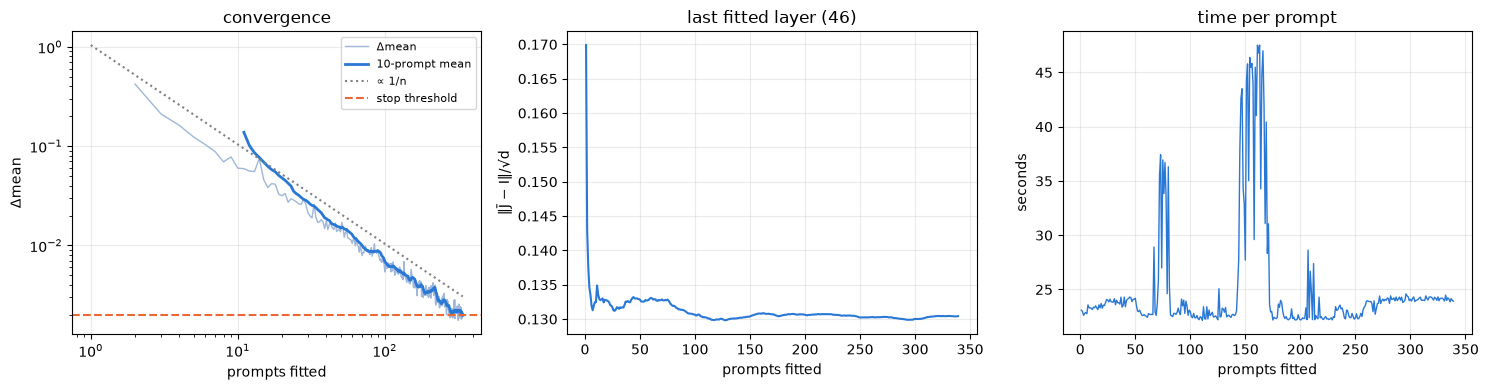

prompts fitted          339.00000
final smoothed Δmean      0.00198
final ‖J̄ − I‖/√d         0.13044
total fit hours           2.34926
first Δmean < 0.01       63.00000
first Δmean < 0.005     129.00000
first Δmean < 0.001           NaN
dtype: float64

In [7]:
curve = pd.read_csv(CSV_PATH)
curve["smoothed"] = curve.mean_rel_change.rolling(STOP["window"]).mean()
milestones = {level: curve.n_done[curve.mean_rel_change < level].min() for level in STOP["levels"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.plot(curve.n_done, curve.mean_rel_change, color="#9fb7d9", lw=1, label="Δmean")
ax.plot(curve.n_done, curve.smoothed, color="#2a78d6", lw=2, label=f"{STOP['window']}-prompt mean")
reference = curve.mean_rel_change.iloc[1:20].mean() * curve.n_done.iloc[1:20].mean()
ax.plot(curve.n_done, reference / curve.n_done, color="gray", ls=":", label="∝ 1/n")
ax.axhline(STOP["stop_at_delta"], color="#eb6834", ls="--", label="stop threshold")
ax.set(xscale="log", yscale="log", xlabel="prompts fitted", ylabel="Δmean", title="convergence")
ax.legend(fontsize=8)
axes[1].plot(curve.n_done, curve.identity_distance, color="#2a78d6")
axes[1].set(xlabel="prompts fitted", ylabel="‖J̄ − I‖/√d", title=f"last fitted layer ({lens.source_layers[-1]})")
axes[2].plot(curve.n_done, curve.elapsed_s, color="#2a78d6", lw=1)
axes[2].set(xlabel="prompts fitted", ylabel="seconds", title="time per prompt")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RUN_DIR / "convergence.png", dpi=140)
plt.show()
display(pd.Series({
    "prompts fitted": int(curve.n_done.iloc[-1]),
    "final smoothed Δmean": curve.smoothed.iloc[-1],
    "final ‖J̄ − I‖/√d": curve.identity_distance.iloc[-1],
    "total fit hours": curve.elapsed_s.sum() / 3600,
    **{f"first Δmean < {level:g}": milestones[level] for level in STOP["levels"]},
}).round(5))

## Conclusions

* **The recipe transfers.** GPT-2 XL converges like the Neuronpedia GPT-2 small fit
  (stopped at 277 prompts): `Δmean` falls roughly as `0.7 / n`, and the stop rule fires at
  339 of the 1000 available prompts. The last fitted layer ends at `‖J̄₄₆ − I‖/√d = 0.130`.
* **fp16 autocast is a negligible approximation here.** Its error on `J` is 2–3 orders of
  magnitude below the prompt-to-prompt variation that the fit averages over, and it makes the
  fit feasible on a V100 (2.35 h instead of ~6 h in fp32).
* **Provenance.** Model revision `15ea56de` (Hub `main`, recorded when the sidecar was
  written), BOS prepended, `max_seq_len=128`, `skip_first=16`, target = final block,
  `dim_batch=8`, Jacobians stored in fp16. Everything is in `lens_provenance.json` next to the
  lens; the convergence curve is `gpt2-xl_convergence.csv` in the Neuronpedia format.

**Limitations.** Deviations from the reference recipe (fp16 autocast instead of bf16 weights,
`dim_batch` 8 instead of 128) are documented above; the stop rule measures convergence of `J`
itself, not of any downstream metric. WikiText's tokenization artifacts are kept, as in the
reference.